# Entrenamiento del modelo

Entrena y evalúa el clasificador con las carpetas de `data/processed/` generadas por `data_setup.ipynb`. Cada versión agrega un cambio sobre una anterior; el análisis de los resultados está en el reporte.

| Versión | Cambio |
|---|---|
| v1 | CNN pequeña entrenada desde cero |
| v2 | v1 + aumento de datos + Dropout |
| v3 | Transfer learning con EfficientNetB0 congelada |
| v4 | v3 + fine-tuning del último bloque |
| v5 | Multi-recorte a 384 px con EfficientNetB0 como extractor de características |
| v6 | v5 entrenada y evaluada en escala de grises (**modelo final**) |
| v7 | v5 con imágenes a color (peso 0.5) y en grises, evaluada en grises |
| v8 | v6 reentrenada con train + val + test (modelo de la interfaz web) |

Métricas: accuracy, top-5 accuracy y F1 macro. Las decisiones se toman con `val`; `test` solo se reporta. El modelo final es la versión con mejor accuracy en `val`. La v8 se entrena con todas las imágenes, así que no tiene métricas.

In [1]:
import json
import time
from pathlib import Path

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from keras import layers
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix, f1_score

ROOT = Path("..")   # los notebooks se corren desde notebooks/

DATA_DIR = ROOT / "data" / "processed"
MODELS_DIR = ROOT / "models"
VERSIONS_DIR = MODELS_DIR / "versions"
FIGURES_DIR = ROOT / "docs" / "figures"
for d in (MODELS_DIR, VERSIONS_DIR, FIGURES_DIR):
    d.mkdir(parents=True, exist_ok=True)

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
RESIZE_HEIGHT = 384   # debe coincidir con el de data_setup (src/app.py lo replica)

keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("Dispositivos:", [d.device_type for d in tf.config.list_physical_devices()])

def savefig(name):
    # guarda cada figura también en docs/figures para usarla en el reporte
    plt.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

TensorFlow 2.21.0 | Keras 3.15.1
Dispositivos: ['CPU']


## 1. Carga de datos

Los nombres de clase se toman de `train` y se fuerzan en `val` y `test` para que los índices coincidan. Las versiones v1–v4 estiran las splash (≈651×384) a 224×224 al cargarlas; v5–v8 las usan completas.

In [2]:
CLASS_NAMES = sorted(p.name for p in (DATA_DIR / "train").iterdir() if p.is_dir())
NUM_CLASSES = len(CLASS_NAMES)

def load_split(split, size=(IMG_SIZE, IMG_SIZE), shuffle=False):
    ds = keras.utils.image_dataset_from_directory(
        DATA_DIR / split,
        class_names=CLASS_NAMES,
        label_mode="int",
        image_size=size,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED,
        verbose=False,
    )
    return ds.cache().prefetch(tf.data.AUTOTUNE)

def labels_of(ds):
    return np.concatenate([y.numpy() for _, y in ds])

train_ds = load_split("train", shuffle=True)
val_ds = load_split("val")
test_ds = load_split("test")
# Si hay archivos que no están en el manifest (por ejemplo copias "foto 2.jpg" de iCloud), detenerse
expected = pd.read_csv(DATA_DIR / "manifest.csv").split.value_counts()
for name, ds in [("train", train_ds), ("val", val_ds), ("test", test_ds)]:
    n = len(labels_of(ds))
    assert n == expected[name], f"{name}: {n} imágenes en disco, {expected[name]} en manifest.csv"
    print(f"{name}: {n} imágenes")
print("Clases:", NUM_CLASSES, "| azar:", f"{1 / NUM_CLASSES:.3f}")

train: 916 imágenes
val: 95 imágenes
test: 95 imágenes
Clases: 38 | azar: 0.026


## 2. Funciones de entrenamiento y evaluación

- `fit`: Adam + `sparse_categorical_crossentropy`, con `EarlyStopping` sobre `val_accuracy` que regresa a los pesos de la mejor época.
- `evaluate`: guarda la versión en `models/versions/` y agrega sus métricas a `results`.

In [3]:
results = []

def compile_model(model, lr):
    model.compile(
        optimizer=keras.optimizers.Adam(lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5")],
    )

def fit(model, name, train, val, epochs, lr, patience=10, initial_epoch=0):
    compile_model(model, lr)
    early_stopping = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=patience,
                                                   restore_best_weights=True)
    start = time.time()
    hist = model.fit(train, validation_data=val, epochs=epochs,
                     initial_epoch=initial_epoch, callbacks=[early_stopping], verbose=2)
    best = int(np.argmax(hist.history["val_accuracy"]))
    print(f"{name}: {time.time() - start:.0f} s | mejor época {initial_epoch + best + 1} "
          f"(val_accuracy {hist.history['val_accuracy'][best]:.3f})")
    return hist

def scores(model, ds):
    y = labels_of(ds)
    probs = model.predict(ds, verbose=0)
    top5 = np.argsort(probs, axis=1)[:, -5:]
    return {
        "acc": float((probs.argmax(1) == y).mean()),
        "top5": float(np.mean([t in row for t, row in zip(y, top5)])),
        "f1": f1_score(y, probs.argmax(1), average="macro", zero_division=0),
    }

def evaluate(model, name, description, hist, val, test, size=(IMG_SIZE, IMG_SIZE), gray=False):
    model.save(VERSIONS_DIR / f"{name}.keras")   # copia de cada versión tal como se evaluó
    v, t = scores(model, val), scores(model, test)
    best = int(np.argmax(hist.history["val_accuracy"]))
    row = {
        "versión": name, "cambio": description, "entrada": f"{size[1]}x{size[0]}" + (" grises" if gray else ""),
        "épocas": len(hist.history["loss"]),
        "train acc": hist.history["accuracy"][best],   # en la época restaurada
        "val acc": v["acc"], "val top5": v["top5"], "val f1": v["f1"],
        "test acc": t["acc"], "test top5": t["top5"], "test f1": t["f1"],
    }
    results.append(row)
    return pd.DataFrame([row]).set_index("versión").round(3)

def plot_history(hist, title):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.5))
    a1.plot(hist.history["loss"], label="train"); a1.plot(hist.history["val_loss"], label="val")
    a2.plot(hist.history["accuracy"], label="train"); a2.plot(hist.history["val_accuracy"], label="val")
    best = int(np.argmax(hist.history["val_accuracy"]))
    for a, metric in [(a1, "loss"), (a2, "accuracy")]:
        a.axvline(best, color="gray", ls="--", lw=1)
        a.set_title(f"{title} - {metric}"); a.set_xlabel("época"); a.legend()
    savefig(f"curvas_{title}")
    plt.show()

## 3. v1: CNN desde cero

Tres bloques `Conv2D` + `MaxPooling2D` y un clasificador denso con softmax.

In [4]:
def build_cnn(augment=None, dropout=0.0):
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augment(inputs) if augment else inputs
    x = layers.Rescaling(1 / 255)(x)
    for filters in [32, 64, 128]:
        x = layers.Conv2D(filters, 3, activation="relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    if dropout:
        x = layers.Dropout(dropout)(x)
    x = layers.Dense(256, activation="relu")(x)
    if dropout:
        x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs)

v1 = build_cnn()
v1.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    22,151,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         9,766 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,254,438 (84.89 MB)

 Trainable params: 22,254,438 (84.89 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30


/Users/emiliolopez/Desktop/Septimo Semestre/lol-champion-classifier.nosync/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


29/29 - 11s - 363ms/step - accuracy: 0.0338 - loss: 3.6839 - top5: 0.1430 - val_accuracy: 0.0211 - val_loss: 3.6373 - val_top5: 0.1368


Epoch 2/30


29/29 - 9s - 322ms/step - accuracy: 0.0459 - loss: 3.6219 - top5: 0.1910 - val_accuracy: 0.0316 - val_loss: 3.6459 - val_top5: 0.1474


Epoch 3/30


... (28 outputs left out)

29/29 - 10s - 351ms/step - accuracy: 1.0000 - loss: 1.8371e-05 - top5: 1.0000 - val_accuracy: 0.0947 - val_loss: 8.2228 - val_top5: 0.2632


Epoch 18/30


29/29 - 9s - 315ms/step - accuracy: 1.0000 - loss: 1.6404e-05 - top5: 1.0000 - val_accuracy: 0.0947 - val_loss: 8.2842 - val_top5: 0.2632


v1: 171 s | mejor época 8 (val_accuracy 0.105)


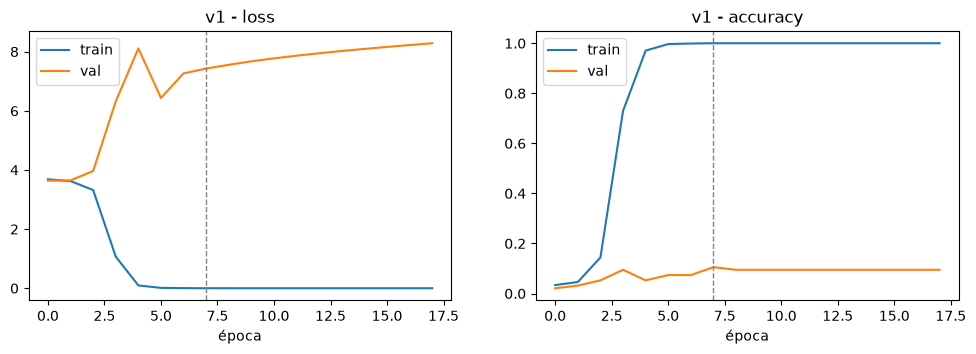

,cambio,entrada,épocas,train acc,val acc,val top5,val f1,test acc,test top5,test f1
versión,,,,,,,,,,
v1,CNN desde cero,224x224,18,1.0,0.105,0.284,0.099,0.105,0.305,0.105


In [5]:
h1 = fit(v1, "v1", train_ds, val_ds, epochs=30, lr=1e-3)
plot_history(h1, "v1")
evaluate(v1, "v1", "CNN desde cero", h1, val_ds, test_ds)

## 4. v2: Aumento de datos + Dropout

Las capas de aumento solo actúan durante el entrenamiento; en `val`/`test` no modifican la imagen.

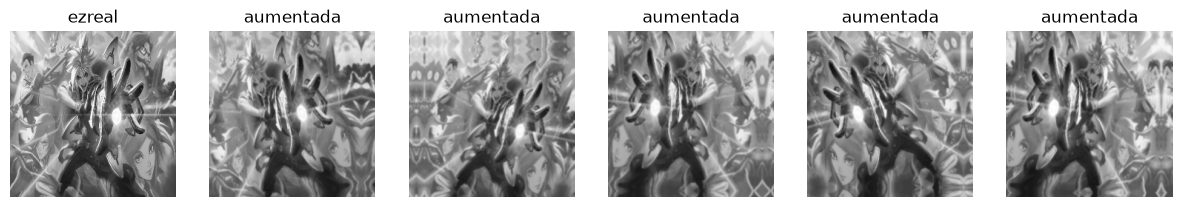

In [6]:
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.2),
], name="augmentation")

# Ejemplos de aumento sobre una imagen de train
images, labels = next(iter(train_ds))
fig, axes = plt.subplots(1, 6, figsize=(15, 2.6))
axes[0].imshow(images[0].numpy().astype("uint8")); axes[0].set_title(CLASS_NAMES[labels[0]])
for ax in axes[1:]:
    ax.imshow(np.clip(augmentation(images[:1], training=True)[0].numpy(), 0, 255).astype("uint8"))
    ax.set_title("aumentada")
for ax in axes:
    ax.axis("off")
savefig("aumento_de_datos")
plt.show()

Epoch 1/60


/Users/emiliolopez/Desktop/Septimo Semestre/lol-champion-classifier.nosync/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


29/29 - 11s - 384ms/step - accuracy: 0.0240 - loss: 3.7853 - top5: 0.1408 - val_accuracy: 0.0316 - val_loss: 3.6373 - val_top5: 0.1474


Epoch 2/60


29/29 - 10s - 341ms/step - accuracy: 0.0186 - loss: 3.6402 - top5: 0.1365 - val_accuracy: 0.0105 - val_loss: 3.6368 - val_top5: 0.1474


Epoch 3/60


... (32 outputs left out)

29/29 - 10s - 341ms/step - accuracy: 0.1157 - loss: 3.2937 - top5: 0.3701 - val_accuracy: 0.0211 - val_loss: 3.6949 - val_top5: 0.1579


Epoch 20/60


29/29 - 10s - 356ms/step - accuracy: 0.1223 - loss: 3.2844 - top5: 0.3679 - val_accuracy: 0.0105 - val_loss: 3.7320 - val_top5: 0.1684


v2: 202 s | mejor época 5 (val_accuracy 0.053)


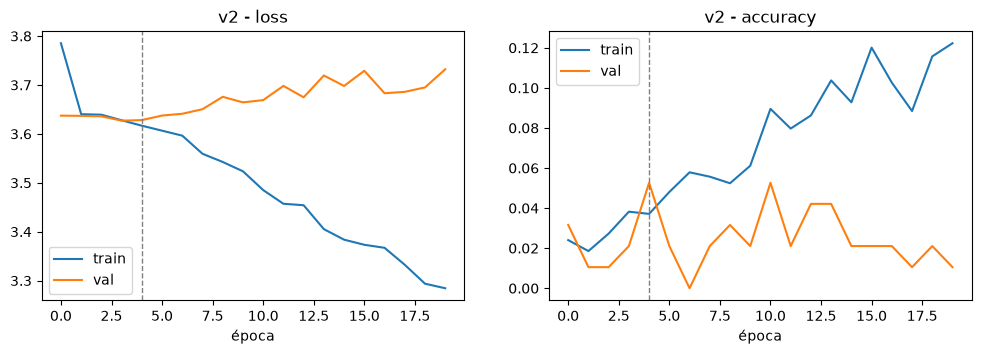

,cambio,entrada,épocas,train acc,val acc,val top5,val f1,test acc,test top5,test f1
versión,,,,,,,,,,
v2,v1 + aumento de datos + Dropout,224x224,20,0.037,0.053,0.137,0.02,0.032,0.179,0.006


In [7]:
v2 = build_cnn(augment=augmentation, dropout=0.5)
h2 = fit(v2, "v2", train_ds, val_ds, epochs=60, lr=1e-3, patience=15)
plot_history(h2, "v2")
evaluate(v2, "v2", "v1 + aumento de datos + Dropout", h2, val_ds, test_ds)

## 5. v3: Transfer learning con EfficientNetB0

- `include_top=False` quita el clasificador de ImageNet y `base.trainable = False` congela la base.
- EfficientNet incluye su propia normalización, así que recibe pixeles en [0, 255] sin `Rescaling`.

In [8]:
def build_transfer(dropout=0.3):
    base = keras.applications.EfficientNetB0(input_shape=(IMG_SIZE, IMG_SIZE, 3),
                                             include_top=False, weights="imagenet")
    base.trainable = False

    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augmentation(inputs)
    x = base(x, training=False)   # BatchNorm de la base siempre en modo inferencia
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs), base

v3, base3 = build_transfer()
v3.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,098,249 (15.63 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Epoch 1/50


/Users/emiliolopez/Desktop/Septimo Semestre/lol-champion-classifier.nosync/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


29/29 - 12s - 419ms/step - accuracy: 0.0404 - loss: 3.7189 - top5: 0.1987 - val_accuracy: 0.0737 - val_loss: 3.5478 - val_top5: 0.2632


Epoch 2/50


29/29 - 7s - 224ms/step - accuracy: 0.1103 - loss: 3.3827 - top5: 0.3417 - val_accuracy: 0.0842 - val_loss: 3.4309 - val_top5: 0.3053


Epoch 3/50


... (36 outputs left out)

29/29 - 7s - 224ms/step - accuracy: 0.6779 - loss: 1.4300 - top5: 0.9170 - val_accuracy: 0.1579 - val_loss: 3.3056 - val_top5: 0.4000


Epoch 22/50


29/29 - 6s - 220ms/step - accuracy: 0.6736 - loss: 1.3928 - top5: 0.9170 - val_accuracy: 0.1579 - val_loss: 3.3227 - val_top5: 0.3684


v3: 148 s | mejor época 12 (val_accuracy 0.189)


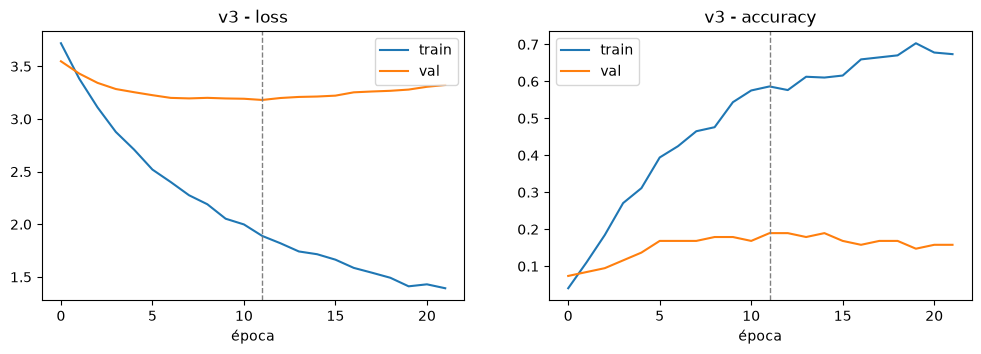

,cambio,entrada,épocas,train acc,val acc,val top5,val f1,test acc,test top5,test f1
versión,,,,,,,,,,
v3,EfficientNetB0 congelada + aumento,224x224,22,0.586,0.189,0.347,0.165,0.137,0.4,0.109


In [9]:
h3 = fit(v3, "v3", train_ds, val_ds, epochs=50, lr=1e-3)
plot_history(h3, "v3")
evaluate(v3, "v3", "EfficientNetB0 congelada + aumento", h3, val_ds, test_ds)

## 6. v4: Fine-tuning

Se parte de los pesos de v3, se descongela desde `block6a` y se entrena con learning rate 1e-5. Las capas `BatchNormalization` se mantienen congeladas.

Capas descongeladas: 59 de 238


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,195,607 (16.00 MB)

 Trainable params: 3,178,562 (12.13 MB)

 Non-trainable params: 919,687 (3.51 MB)

... (25 outputs left out)

29/29 - 9s - 314ms/step - accuracy: 0.6747 - loss: 1.2188 - top5: 0.9203 - val_accuracy: 0.1789 - val_loss: 3.4622 - val_top5: 0.3684


Epoch 35/62


29/29 - 9s - 296ms/step - accuracy: 0.6867 - loss: 1.2420 - top5: 0.9127 - val_accuracy: 0.1684 - val_loss: 3.4696 - val_top5: 0.3684


v4: 121 s | mejor época 25 (val_accuracy 0.200)


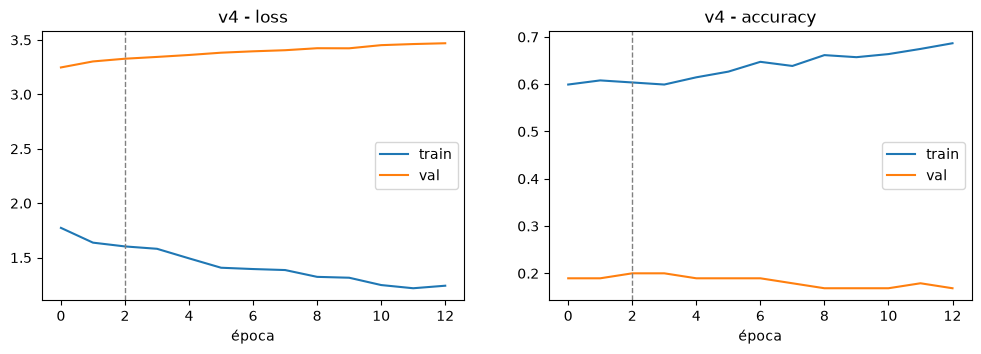

,cambio,entrada,épocas,train acc,val acc,val top5,val f1,test acc,test top5,test f1
versión,,,,,,,,,,
v4,v3 + fine-tuning desde block6a,224x224,13,0.604,0.2,0.368,0.168,0.137,0.389,0.096


In [10]:
v4, base4 = v3, base3   # se continúa desde v3 (ya guardada en models/versions/v3.keras)

first = next(i for i, l in enumerate(base4.layers) if l.name.startswith("block6a"))
base4.trainable = True
for i, layer in enumerate(base4.layers):
    layer.trainable = i >= first and not isinstance(layer, layers.BatchNormalization)
print(f"Capas descongeladas: {sum(l.trainable for l in base4.layers)} de {len(base4.layers)}")
v4.summary()

start_epoch = len(h3.history["loss"])
h4 = fit(v4, "v4", train_ds, val_ds, epochs=start_epoch + 40, lr=1e-5, initial_epoch=start_epoch)
plot_history(h4, "v4")
evaluate(v4, "v4", "v3 + fine-tuning desde block6a", h4, val_ds, test_ds)

## 7. v5: Multi-recorte a 384 px

La splash de 651×384 se divide en tres recortes de 384×384 (izquierda, centro y derecha) que pasan por la misma EfficientNetB0; sus características se concatenan.

Como la base está congelada, las características se calculan una sola vez y solo se entrena el clasificador sobre ellas. Por eso no hay aumento aleatorio: se agrega una copia volteada de cada imagen de `train`. Al final, extractor y clasificador se unen en un solo modelo que recibe la splash completa.

Entrada: 651x384 -> 3 recortes de 384x384 -> 3840 características


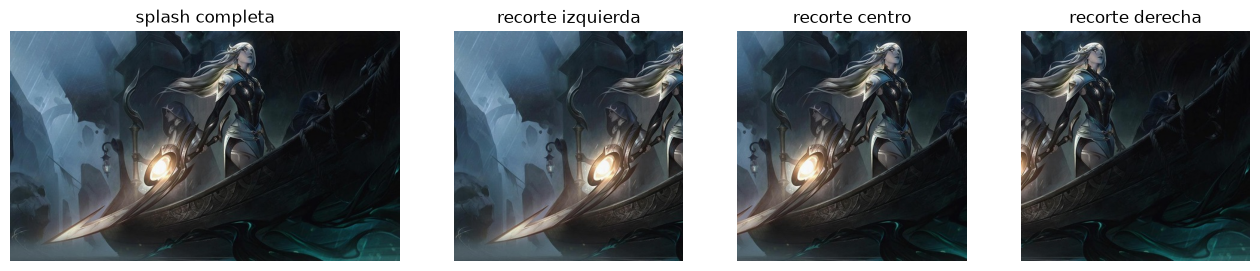

In [11]:
V5_HEIGHT = RESIZE_HEIGHT
V5_WIDTH = Image.open(next((DATA_DIR / "train").rglob("*.jpg"))).size[0]   # ancho de las splash guardadas
V5_SIZE = (V5_HEIGHT, V5_WIDTH)

def build_multicrop_extractor():
    base = keras.applications.EfficientNetB0(input_shape=(V5_HEIGHT, V5_HEIGHT, 3), include_top=False,
                                             weights="imagenet", pooling="avg")
    base.trainable = False

    inputs = keras.Input((V5_HEIGHT, V5_WIDTH, 3))
    extra = V5_WIDTH - V5_HEIGHT   # pixeles que sobran a lo ancho para un cuadrado
    crops = [
        layers.Cropping2D(((0, 0), (0, extra)), name="recorte_izquierda")(inputs),
        layers.Cropping2D(((0, 0), (extra // 2, extra - extra // 2)), name="recorte_centro")(inputs),
        layers.Cropping2D(((0, 0), (extra, 0)), name="recorte_derecha")(inputs),
    ]
    features = [base(c, training=False) for c in crops]   # misma red y mismos pesos para los tres
    return keras.Model(inputs, layers.Concatenate(name="caracteristicas")(features),
                       name="extractor_multirecorte")

extractor = build_multicrop_extractor()
print(f"Entrada: {V5_WIDTH}x{V5_HEIGHT} -> 3 recortes de {V5_HEIGHT}x{V5_HEIGHT} -> {extractor.output_shape[-1]} características")

# Cómo se ve una splash dividida en los tres recortes
img = Image.open(next((DATA_DIR / "test").rglob("*.jpg")))
fig, axes = plt.subplots(1, 4, figsize=(16, 3), gridspec_kw={"width_ratios": [1.7, 1, 1, 1]})
axes[0].imshow(img); axes[0].set_title("splash completa")
extra = V5_WIDTH - V5_HEIGHT
for ax, (name, left) in zip(axes[1:], [("izquierda", 0), ("centro", extra // 2), ("derecha", extra)]):
    ax.imshow(img.crop((left, 0, left + V5_HEIGHT, V5_HEIGHT))); ax.set_title(f"recorte {name}")
for ax in axes:
    ax.axis("off")
savefig("multirecorte")
plt.show()

In [12]:
def extract(ds, flip=False):
    X, Y = [], []
    for x, y in ds:
        if flip:
            x = tf.reverse(x, axis=[2])   # volteo horizontal
        X.append(extractor(x, training=False).numpy())
        Y.append(y.numpy())
    return np.concatenate(X), np.concatenate(Y)

start = time.time()
train_v5 = load_split("train", V5_SIZE)
val_v5 = load_split("val", V5_SIZE)
test_v5 = load_split("test", V5_SIZE)

X_train, y_train = extract(train_v5)
X_flip, _ = extract(train_v5, flip=True)
X_val, y_val = extract(val_v5)
X_train = np.concatenate([X_train, X_flip])
y_train = np.concatenate([y_train, y_train])
print(f"Características: train {X_train.shape}, val {X_val.shape} | {time.time() - start:.0f} s")

Características: train (1832, 3840), val (95, 3840) | 459 s


Epoch 1/300


/Users/emiliolopez/Desktop/Septimo Semestre/lol-champion-classifier.nosync/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


58/58 - 0s - 8ms/step - accuracy: 0.1878 - loss: 3.1268 - top5: 0.4509 - val_accuracy: 0.1263 - val_loss: 3.0495 - val_top5: 0.4632


Epoch 2/300


58/58 - 0s - 1ms/step - accuracy: 0.5928 - loss: 1.7501 - top5: 0.8805 - val_accuracy: 0.1368 - val_loss: 2.9317 - val_top5: 0.5368


Epoch 3/300


... (76 outputs left out)

58/58 - 0s - 1ms/step - accuracy: 0.9940 - loss: 0.0276 - top5: 1.0000 - val_accuracy: 0.2105 - val_loss: 3.5213 - val_top5: 0.5579


Epoch 42/300


58/58 - 0s - 1ms/step - accuracy: 0.9940 - loss: 0.0221 - top5: 1.0000 - val_accuracy: 0.2105 - val_loss: 3.5128 - val_top5: 0.5789


v5: 3 s | mejor época 12 (val_accuracy 0.242)


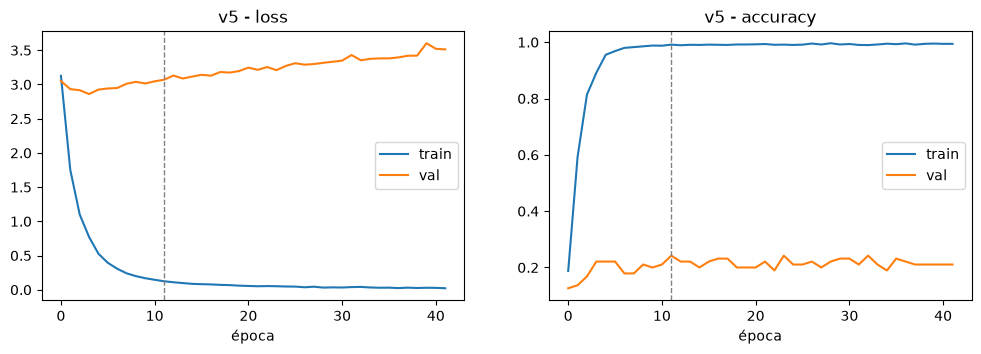

Model: "v5_multirecorte"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6       │ (None, 384, 651,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ recorte_izquierda   │ (None, 384, 384,  │          0 │ input_layer_6[0]… │
│ (Cropping2D)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ recorte_centro      │ (None, 384, 384,  │          0 │ input_layer_6[0]… │
│ (Cropping2D)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ recorte_derecha     │ (None, 384, 384,  │          0 │ input_layer_6[0]… │
│ (Cropping2D)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 1280)      │  4,049,571 │ recorte_izquierd… │
│ (Functional)        │                   │            │ recorte_centro[0… │
│                     │                   │            │ recorte_derecha[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ caracteristicas     │ (None, 3840)      │          0 │ efficientnetb0[0… │
│ (Concatenate)       │                   │            │ efficientnetb0[1… │
│                     │                   │            │ efficientnetb0[2… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ clasificador        │ (None, 38)        │    145,958 │ caracteristicas[… │
│ (Sequential)        │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,195,529 (16.00 MB)

 Trainable params: 145,958 (570.15 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

,cambio,entrada,épocas,train acc,val acc,val top5,val f1,test acc,test top5,test f1
versión,,,,,,,,,,
v5,3 recortes 384px + EfficientNetB0 (extractor) ...,651x384,42,0.991,0.242,0.589,0.207,0.242,0.505,0.227


In [13]:
keras.utils.set_random_seed(SEED)
feat_train = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(len(X_train), seed=SEED).batch(BATCH_SIZE)
feat_val = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH_SIZE)

def build_head():
    return keras.Sequential([
        keras.Input(X_train.shape[1:]),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name="clasificador")

head = build_head()

h5 = fit(head, "v5", feat_train, feat_val, epochs=300, lr=1e-3, patience=30)
plot_history(h5, "v5")

# Modelo completo: splash de 651×384 -> tres recortes -> EfficientNetB0 -> clasificador
v5 = keras.Model(extractor.input, head(extractor.output), name="v5_multirecorte")
v5.summary()   # v6–v8 tienen la misma arquitectura y el mismo número de parámetros
evaluate(v5, "v5", f"3 recortes {V5_HEIGHT}px + EfficientNetB0 (extractor) + clasificador",
         h5, val_v5, test_v5, size=V5_SIZE)

## 8. Diagnóstico: ¿el modelo depende del color?

Se evalúa la v5, tal como se entrenó, con `val` y `test` convertidos a grises. `grayscale_to_rgb` repite el canal tres veces porque EfficientNetB0 espera 3 canales.

In [14]:
def to_gray(x, y):
    return tf.image.grayscale_to_rgb(tf.image.rgb_to_grayscale(x)), y

val_gray = val_v5.map(to_gray)
test_gray = test_v5.map(to_gray)

pd.DataFrame([
    {"split": name, "acc color": scores(v5, ds)["acc"], "acc grises": scores(v5, ds_gray)["acc"]}
    for name, ds, ds_gray in [("val", val_v5, val_gray), ("test", test_v5, test_gray)]
]).set_index("split").round(3)

,acc color,acc grises
split,,
val,0.242,0.295
test,0.242,0.295


## 9. v6: Entrenar y evaluar en escala de grises

Misma v5, cambiando solo los datos:
- **Train:** solo las copias `_bw` y su volteo. Sus características ya están en `X_train`, porque `train_v5` se cargó sin barajar; basta con filtrar sus filas.
- **Val y test:** convertidos a grises.

Características: train (916, 3840) (solo _bw), val (95, 3840) (grises)
Epoch 1/300


/Users/emiliolopez/Desktop/Septimo Semestre/lol-champion-classifier.nosync/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


29/29 - 0s - 13ms/step - accuracy: 0.0830 - loss: 3.5771 - top5: 0.2828 - val_accuracy: 0.1368 - val_loss: 3.3504 - val_top5: 0.3684


Epoch 2/300


29/29 - 0s - 1ms/step - accuracy: 0.4138 - loss: 2.3901 - top5: 0.7238 - val_accuracy: 0.1684 - val_loss: 3.0887 - val_top5: 0.5053


Epoch 3/300


... (92 outputs left out)

29/29 - 0s - 1ms/step - accuracy: 0.9934 - loss: 0.0360 - top5: 1.0000 - val_accuracy: 0.2947 - val_loss: 3.0142 - val_top5: 0.5579


Epoch 50/300


29/29 - 0s - 1ms/step - accuracy: 0.9945 - loss: 0.0300 - top5: 1.0000 - val_accuracy: 0.2632 - val_loss: 3.0551 - val_top5: 0.5789


v6: 2 s | mejor época 20 (val_accuracy 0.316)


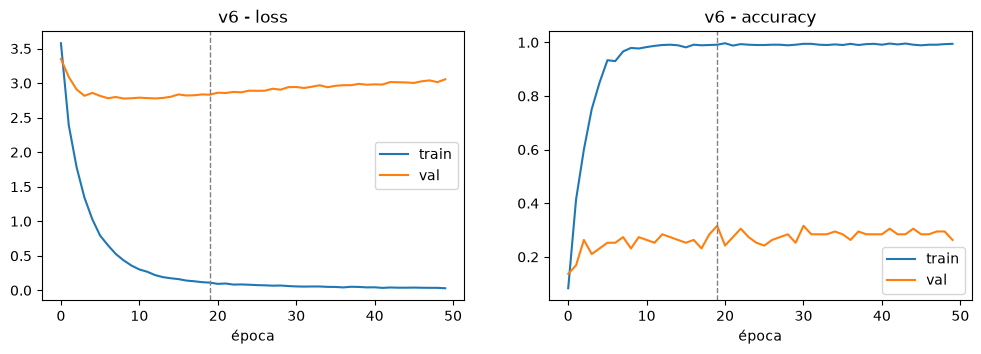

,cambio,entrada,épocas,train acc,val acc,val top5,val f1,test acc,test top5,test f1
versión,,,,,,,,,,
v6,v5 entrenada y evaluada en grises (solo _bw),651x384 grises,50,0.991,0.316,0.579,0.278,0.263,0.526,0.23


In [15]:
# Qué filas de X_train son copias _bw (X_train = originales + volteadas, en el mismo orden)
train_paths = keras.utils.image_dataset_from_directory(
    DATA_DIR / "train", class_names=CLASS_NAMES, image_size=V5_SIZE, shuffle=False, verbose=False,
).file_paths
is_bw = np.array([Path(p).stem.endswith("_bw") for p in train_paths])
is_bw = np.concatenate([is_bw, is_bw])
assert len(is_bw) == len(X_train)

X_train6, y_train6 = X_train[is_bw], y_train[is_bw]
X_val_gray, y_val_gray = extract(val_gray)
print(f"Características: train {X_train6.shape} (solo _bw), val {X_val_gray.shape} (grises)")

keras.utils.set_random_seed(SEED)
feat_train6 = tf.data.Dataset.from_tensor_slices((X_train6, y_train6)).shuffle(len(X_train6), seed=SEED).batch(BATCH_SIZE)
feat_val_gray = tf.data.Dataset.from_tensor_slices((X_val_gray, y_val_gray)).batch(BATCH_SIZE)

head6 = build_head()
h6 = fit(head6, "v6", feat_train6, feat_val_gray, epochs=300, lr=1e-3, patience=30)
plot_history(h6, "v6")

v6 = keras.Model(extractor.input, head6(extractor.output), name="v6_grises")
evaluate(v6, "v6", "v5 entrenada y evaluada en grises (solo _bw)", h6, val_gray, test_gray,
         size=V5_SIZE, gray=True)

## 10. v7: Color y grises con más peso a los grises

Se entrena con todas las imágenes de `train` (a color y `_bw`, más sus volteos), pero las de color pesan `COLOR_WEIGHT` en la pérdida (`sample_weight`). Se evalúa en grises, igual que la v6.

Ejemplos: 1832 (916 _bw con peso 1, 916 a color con peso 0.5)
Epoch 1/300


/Users/emiliolopez/Desktop/Septimo Semestre/lol-champion-classifier.nosync/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


58/58 - 0s - 7ms/step - accuracy: 0.1867 - loss: 2.3777 - top5: 0.4416 - val_accuracy: 0.0632 - val_loss: 3.1334 - val_top5: 0.4000


Epoch 2/300


58/58 - 0s - 1ms/step - accuracy: 0.5639 - loss: 1.3573 - top5: 0.8723 - val_accuracy: 0.2211 - val_loss: 2.9125 - val_top5: 0.5474


Epoch 3/300


... (118 outputs left out)

58/58 - 0s - 1ms/step - accuracy: 0.9945 - loss: 0.0167 - top5: 1.0000 - val_accuracy: 0.2632 - val_loss: 3.3490 - val_top5: 0.5895


Epoch 63/300


58/58 - 0s - 1ms/step - accuracy: 0.9962 - loss: 0.0126 - top5: 1.0000 - val_accuracy: 0.2842 - val_loss: 3.3301 - val_top5: 0.6000


v7: 4 s | mejor época 33 (val_accuracy 0.305)


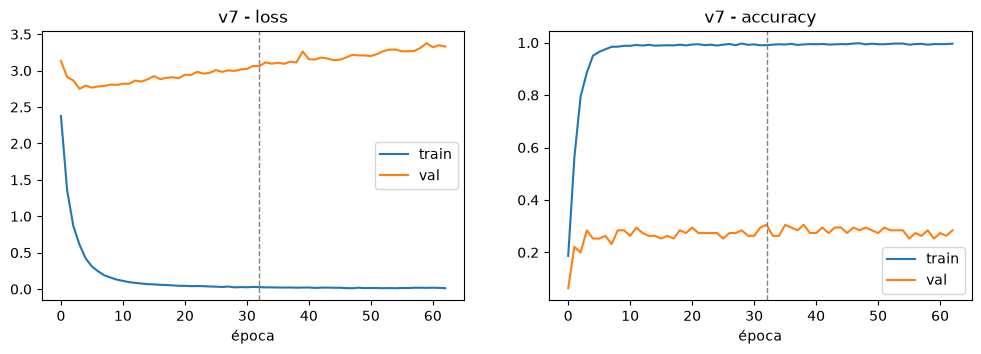

,cambio,entrada,épocas,train acc,val acc,val top5,val f1,test acc,test top5,test f1
versión,,,,,,,,,,
v7,"v5 con color (peso 0.5) + _bw, evaluada en grises",651x384 grises,63,0.991,0.305,0.6,0.283,0.295,0.505,0.279


In [16]:
COLOR_WEIGHT = 0.5
w_train7 = np.where(is_bw, 1.0, COLOR_WEIGHT)
print(f"Ejemplos: {len(X_train)} ({int(is_bw.sum())} _bw con peso 1, {int((~is_bw).sum())} a color con peso {COLOR_WEIGHT})")

keras.utils.set_random_seed(SEED)
feat_train7 = (tf.data.Dataset.from_tensor_slices((X_train, y_train, w_train7))
               .shuffle(len(X_train), seed=SEED).batch(BATCH_SIZE))

head7 = build_head()
h7 = fit(head7, "v7", feat_train7, feat_val_gray, epochs=300, lr=1e-3, patience=30)
plot_history(h7, "v7")

v7 = keras.Model(extractor.input, head7(extractor.output), name="v7_color_grises")
evaluate(v7, "v7", f"v5 con color (peso {COLOR_WEIGHT}) + _bw, evaluada en grises", h7, val_gray, test_gray,
         size=V5_SIZE, gray=True)

## 11. v8: v6 reentrenada con train + val + test

Una vez elegido el modelo con `val` y medido en `test`, se reentrena la misma configuración con todas las imágenes (más sus volteos) para usarla en la interfaz web. Sin datos de validación, se entrena el número de épocas de la mejor época de la v6. Como no queda ninguna imagen sin usar, la v8 no tiene métricas: las que se reportan son las de la v6.

In [17]:
BEST_EPOCHS = int(np.argmax(h6.history["val_accuracy"])) + 1

X_val_gray_flip, _ = extract(val_gray, flip=True)
X_test_gray, y_test_gray = extract(test_gray)
X_test_gray_flip, _ = extract(test_gray, flip=True)
X_all = np.concatenate([X_train6, X_val_gray, X_val_gray_flip, X_test_gray, X_test_gray_flip])
y_all = np.concatenate([y_train6, y_val_gray, y_val_gray, y_test_gray, y_test_gray])
print(f"Épocas: {BEST_EPOCHS} | ejemplos de entrenamiento: v6 {len(X_train6)} -> v8 {len(X_all)}")

keras.utils.set_random_seed(SEED)
feat_all = tf.data.Dataset.from_tensor_slices((X_all, y_all)).shuffle(len(X_all), seed=SEED).batch(BATCH_SIZE)
head8 = build_head()
compile_model(head8, 1e-3)
h8 = head8.fit(feat_all, epochs=BEST_EPOCHS, verbose=0)

v8 = keras.Model(extractor.input, head8(extractor.output), name="v8_todos_los_datos")
v8.save(VERSIONS_DIR / "v8.keras")
results.append({
    "versión": "v8", "cambio": "v6 reentrenada con train + val + test", "entrada": f"{V5_WIDTH}x{V5_HEIGHT} grises",
    "épocas": BEST_EPOCHS, "train acc": h8.history["accuracy"][-1],
    "val acc": np.nan, "val top5": np.nan, "val f1": np.nan,     # val y test se usaron para entrenar
    "test acc": np.nan, "test top5": np.nan, "test f1": np.nan,
})

Épocas: 20 | ejemplos de entrenamiento: v6 916 -> v8 1296


/Users/emiliolopez/Desktop/Septimo Semestre/lol-champion-classifier.nosync/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


## 12. Comparación de versiones

La v8 no aparece en la gráfica porque no tiene métricas.

In [18]:
table = pd.DataFrame(results).set_index("versión").round(3)
table

,cambio,entrada,épocas,train acc,val acc,val top5,val f1,test acc,test top5,test f1
versión,,,,,,,,,,
v1,CNN desde cero,224x224,18,1.000,0.105,0.284,0.099,0.105,0.305,0.105
v2,v1 + aumento de datos + Dropout,224x224,20,0.037,0.053,0.137,0.020,0.032,0.179,0.006
v3,EfficientNetB0 congelada + aumento,224x224,22,0.586,0.189,0.347,0.165,0.137,0.400,0.109
v4,v3 + fine-tuning desde block6a,224x224,13,0.604,0.200,0.368,0.168,0.137,0.389,0.096
v5,3 recortes 384px + EfficientNetB0 (extractor) ...,651x384,42,0.991,0.242,0.589,0.207,0.242,0.505,0.227
v6,v5 entrenada y evaluada en grises (solo _bw),651x384 grises,50,0.991,0.316,0.579,0.278,0.263,0.526,0.230
v7,"v5 con color (peso 0.5) + _bw, evaluada en grises",651x384 grises,63,0.991,0.305,0.600,0.283,0.295,0.505,0.279
v8,v6 reentrenada con train + val + test,651x384 grises,20,0.987,NaN,NaN,NaN,NaN,NaN,NaN


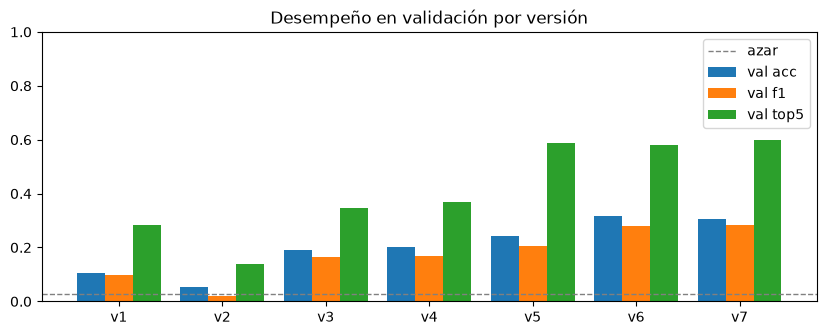

In [19]:
measured = table.dropna(subset=["val acc"])
fig, ax = plt.subplots(figsize=(10, 3.5))
x = np.arange(len(measured))
for offset, col in [(-0.27, "val acc"), (0, "val f1"), (0.27, "val top5")]:
    ax.bar(x + offset, measured[col], 0.27, label=col)
ax.axhline(1 / NUM_CLASSES, color="gray", ls="--", lw=1, label="azar")
ax.set_xticks(x, measured.index)
ax.set_ylim(0, 1)
ax.set_title("Desempeño en validación por versión")
ax.legend()
savefig("comparacion_versiones")
plt.show()

## 13. Análisis del modelo final en test

El modelo final es la versión con mejor accuracy en `val`.

In [20]:
final_name = table["val acc"].idxmax()   # la v8 no tiene val acc y no entra en la comparación
# La v8 reentrena la configuración de la v6; si gana otra versión, hay que reentrenar esa en su lugar
assert final_name == "v6", f"la mejor en val es {final_name}, no la v6"
final = keras.models.load_model(VERSIONS_DIR / f"{final_name}.keras")
test_ds = test_gray
print("Modelo final:", final_name)

y_true = labels_of(test_ds)
probs = final.predict(test_ds, verbose=0)
y_pred = probs.argmax(axis=1)
top5 = np.argsort(probs, axis=1)[:, -5:]

print(f"Test accuracy: {(y_pred == y_true).mean():.3f}")
print(f"Test top-5:    {np.mean([t in row for t, row in zip(y_true, top5)]):.3f}")
print(f"Test F1 macro: {f1_score(y_true, y_pred, average='macro', zero_division=0):.3f}")

Modelo final: v6


Test accuracy: 0.263
Test top-5:    0.526
Test F1 macro: 0.230


In [21]:
# Precisión, recall y F1 por campeón
report = pd.DataFrame(classification_report(
    y_true, y_pred, labels=range(NUM_CLASSES), target_names=CLASS_NAMES,
    output_dict=True, zero_division=0)).T.iloc[:NUM_CLASSES]

print("Campeones con F1 = 0 en test:", (report["f1-score"] == 0).sum(), "de", NUM_CLASSES)
print("\nMejores campeones:")
print(report.sort_values("f1-score", ascending=False).head(8).round(2).to_string())
print("\nPeores campeones:")
print(report.sort_values("f1-score").head(8).round(2).to_string())

Campeones con F1 = 0 en test: 19 de 38

Mejores campeones:
              precision  recall  f1-score  support
annie               1.0    0.67      0.80      3.0
blitzcrank          1.0    0.67      0.80      3.0
lee_sin             0.5    0.67      0.57      3.0
sona                0.4    1.00      0.57      2.0
miss_fortune        0.4    0.67      0.50      3.0
warwick             0.5    0.50      0.50      2.0
soraka              0.5    0.50      0.50      2.0
garen               0.5    0.50      0.50      2.0

Peores campeones:
           precision  recall  f1-score  support
ahri             0.0     0.0       0.0      3.0
veigar           0.0     0.0       0.0      2.0
sivir            0.0     0.0       0.0      3.0
shaco            0.0     0.0       0.0      2.0
riven            0.0     0.0       0.0      2.0
nidalee          0.0     0.0       0.0      2.0
master_yi        0.0     0.0       0.0      3.0
karma            0.0     0.0       0.0      2.0


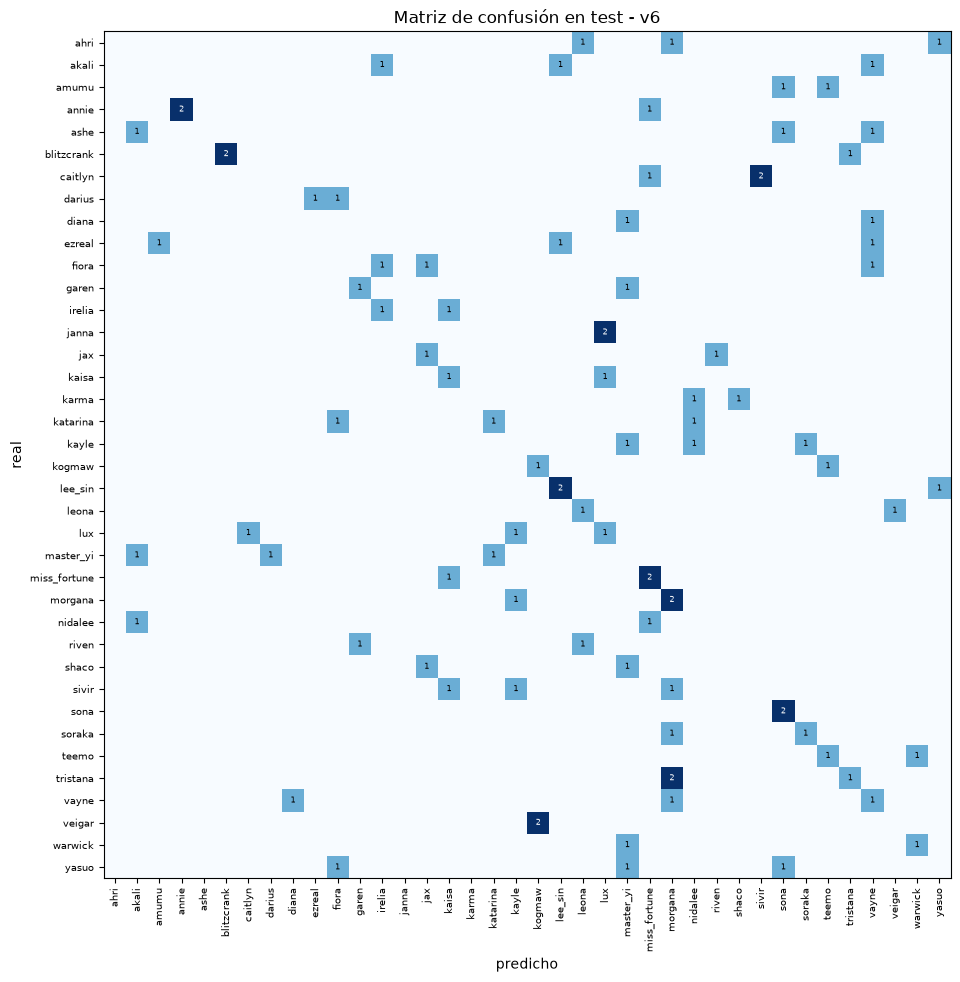

Campeones más predichos por error:
predicho
morgana         6
master_yi       6
vayne           5
sona            3
miss_fortune    3


real      predicho
caitlyn   sivir       2
janna     lux         2
tristana  morgana     2
veigar    kogmaw      2
ahri      morgana     1
          yasuo       1
          leona       1
akali     vayne       1
          irelia      1
          lee_sin     1
Name: count, dtype: int64

In [22]:
cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
fig, ax = plt.subplots(figsize=(12, 11))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=90, fontsize=7)
ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES, fontsize=7)
ax.set_xlabel("predicho"); ax.set_ylabel("real")
ax.set_title(f"Matriz de confusión en test - {final_name}")
for i, j in zip(*np.nonzero(cm)):
    ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=6,
            color="white" if cm[i, j] > cm.max() / 2 else "black")
savefig("matriz_confusion")
plt.show()

# Errores más comunes y campeones a los que más se les asignan predicciones equivocadas
errors = pd.DataFrame({"real": [CLASS_NAMES[i] for i in y_true],
                       "predicho": [CLASS_NAMES[i] for i in y_pred]})
errors = errors[errors.real != errors.predicho]
print("Campeones más predichos por error:")
print(errors.predicho.value_counts().head(5).to_string())
errors.value_counts().head(10)

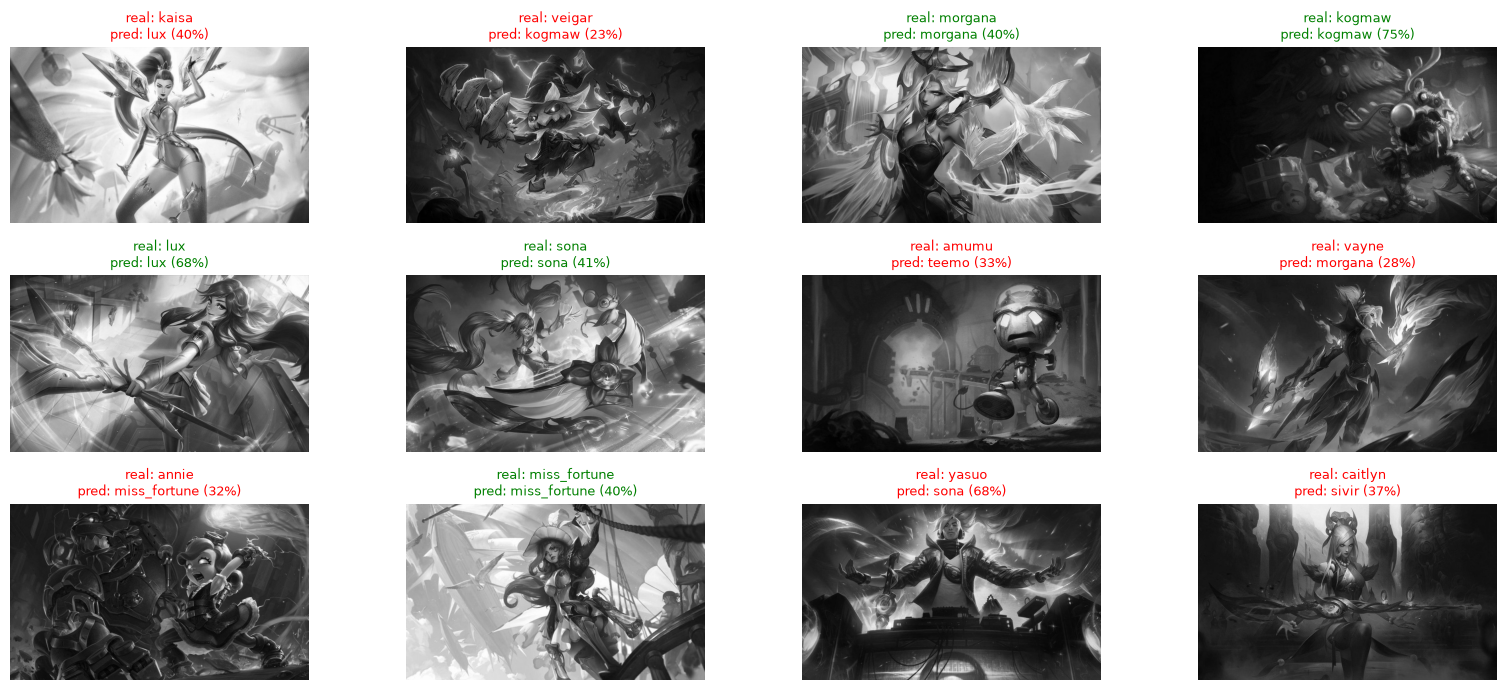

In [23]:
# Ejemplos de predicciones en test
images = np.concatenate([x.numpy() for x, _ in test_ds])
rng = np.random.default_rng(SEED)
idx = rng.choice(len(images), 12, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(16, 7))
for ax, i in zip(axes.flat, idx):
    ax.imshow(images[i].astype("uint8"))
    ok = y_pred[i] == y_true[i]
    ax.set_title(f"real: {CLASS_NAMES[y_true[i]]}\npred: {CLASS_NAMES[y_pred[i]]} ({probs[i].max():.0%})",
                 fontsize=9, color="green" if ok else "red")
    ax.axis("off")
plt.tight_layout()
savefig("ejemplos_test")
plt.show()

## 14. Guardar el modelo de la interfaz web

Se guardan la v8 (`.keras`) y `metadata.json` con las clases y el preprocesamiento que necesita `src/app.py`.

In [24]:
v8.save(MODELS_DIR / "lol_champion_classifier.keras")
with open(MODELS_DIR / "metadata.json", "w") as f:
    json.dump({"class_names": CLASS_NAMES, "input_size": list(V5_SIZE),
               "resize_height": RESIZE_HEIGHT, "grayscale": True,
               "version": "v8"}, f, indent=1)
print("Guardado en", MODELS_DIR)

Guardado en ../models
